# TPCC Query and Transaction Latency Analysis

This notebook analyzes latency from the uninstrumented TPCC throughput run. It separates transaction-level latency (`raw.csv` and per-procedure result windows) from SQL-shape latency (`dbfs_query_trace.csv` or `postgres_query_trace.csv`).

Configure `throughput_comparison_root` to either an engine result directory containing the BenchBase artifacts directly or a comparison directory containing `dbfs/` and `postgres/`.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use('ggplot')
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

throughput_comparison_root = Path(
    '/Users/yohasebe/Documents/dbfs/benchmarking/results/20260913-103940_postgres_comp_th/tpcc'
)

throughput_dbfs_candidate = throughput_comparison_root / 'dbfs'
throughput_dbfs_result_dir = (throughput_dbfs_candidate if any(
    throughput_dbfs_candidate.glob('*.summary.json')) else
                              throughput_comparison_root)

run_configs = {
    'dbfs': {
        'display_name': 'dbfs',
        'result_dir': throughput_dbfs_result_dir,
    },
    'postgres': {
        'display_name': 'PostgreSQL',
        'result_dir': throughput_comparison_root / 'postgres',
    },
}
run_configs = {
    engine: config
    for engine, config in run_configs.items()
    if (config['result_dir'].is_dir()
        and any(config['result_dir'].glob('*.summary.json')))
}
if not run_configs:
    raise FileNotFoundError(
        f'No completed TPCC results found under {throughput_comparison_root}')

missing_engines = sorted({'dbfs', 'postgres'} - set(run_configs))
if missing_engines:
    print('Skipping engines without results: ' + ', '.join(missing_engines))

transaction_names = [
    'NewOrder', 'Payment', 'OrderStatus', 'Delivery', 'StockLevel'
]
query_trace_filenames = {
    'dbfs': 'dbfs_query_trace.csv',
    'postgres': 'postgres_query_trace.csv',
}
engine_colors = {'dbfs': 'tab:blue', 'postgres': 'tab:orange'}
engine_markers = {'dbfs': 'o', 'postgres': 'x'}

In [2]:
required_suffixes = {
    'summary': '.summary.json',
    'results': '.results.csv',
    'raw': '.raw.csv',
}
procedure_suffix = '.results.'


def find_latest_artifact_prefix(result_dir):
    summaries = sorted(result_dir.glob('*' + required_suffixes['summary']))
    if not summaries:
        raise FileNotFoundError(
            f'No summary artifact found under {result_dir}')
    return summaries[-1].name[:-len(required_suffixes['summary'])]


def load_run(engine, config):
    result_dir = config['result_dir']
    label = find_latest_artifact_prefix(result_dir)
    artifacts = {
        name: result_dir / f'{label}{suffix}'
        for name, suffix in required_suffixes.items()
    }
    with artifacts['summary'].open() as handle:
        summary = json.load(handle)

    procedure_dfs = {
        path.stem.split('.results.', 1)[1]: pd.read_csv(path)
        for path in sorted(result_dir.glob(f'{label}{procedure_suffix}*.csv'))
    }
    trace_path = result_dir / query_trace_filenames[engine]
    query_trace_df = pd.read_csv(trace_path) if trace_path.exists() else None

    return {
        **config,
        'label': label,
        'summary': summary,
        'results_df': pd.read_csv(artifacts['results']),
        'raw_df': pd.read_csv(artifacts['raw']),
        'procedure_dfs': procedure_dfs,
        'query_trace_path': trace_path,
        'query_trace_df': query_trace_df,
    }


runs = {
    engine: load_run(engine, config)
    for engine, config in run_configs.items()
}
validation_df = pd.DataFrame([{
    'Engine':
    run['display_name'],
    'Run Label':
    run['label'],
    'Raw Requests':
    len(run['raw_df']),
    'Procedure Files':
    len(run['procedure_dfs']),
    'Query Trace':
    str(run['query_trace_path']),
    'Query Trace Rows':
    0 if run['query_trace_df'] is None else len(run['query_trace_df']),
} for run in runs.values()])
validation_df

,Engine,Run Label,Raw Requests,Procedure Files,Query Trace,Query Trace Rows
0,dbfs,tpcc_2026-09-13_01-46-21,91238,5,/Users/yohasebe/Documents/dbfs/benchmarking/re...,31
1,PostgreSQL,tpcc_2026-09-13_01-54-25,159816,5,/Users/yohasebe/Documents/dbfs/benchmarking/re...,41


## Overall transaction latency

The table uses the BenchBase summary, while the time-series plot uses five-second result windows.

In [3]:
overall_latency_rows = []
for run in runs.values():
    summary = run['summary']
    latency = summary['Latency Distribution']
    overall_latency_rows.append({
        'Engine':
        run['display_name'],
        'Measured Requests':
        summary['Measured Requests'],
        'Average (ms)':
        latency['Average Latency (microseconds)'] / 1000,
        'Median (ms)':
        latency['Median Latency (microseconds)'] / 1000,
        'P95 (ms)':
        latency['95th Percentile Latency (microseconds)'] / 1000,
        'P99 (ms)':
        latency['99th Percentile Latency (microseconds)'] / 1000,
        'Maximum (ms)':
        latency['Maximum Latency (microseconds)'] / 1000,
    })

overall_latency_df = pd.DataFrame(overall_latency_rows).set_index('Engine')
overall_latency_df

,Measured Requests,Average (ms),Median (ms),P95 (ms),P99 (ms),Maximum (ms)
Engine,,,,,,
dbfs,91238,3.277,2.623,8.608,13.642,536.282
PostgreSQL,159816,1.868,1.435,5.037,6.984,430.295


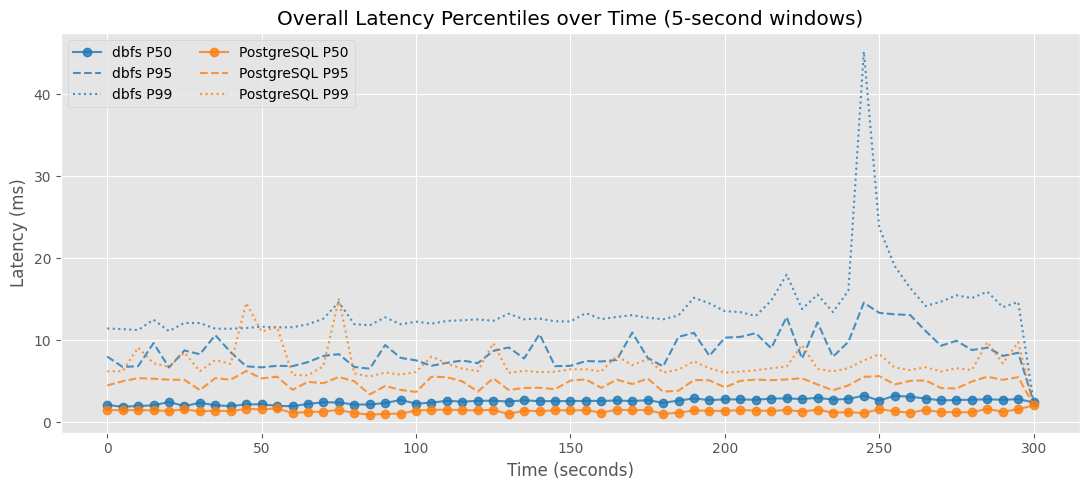

In [4]:
fig, axis = plt.subplots(figsize=(11, 5))
for engine, run in runs.items():
    results_df = run['results_df']
    label = run['display_name']
    color = engine_colors[engine]
    axis.plot(results_df['Time (seconds)'],
              results_df['Median Latency (millisecond)'],
              marker='o',
              color=color,
              alpha=0.8,
              label=f'{label} P50')
    axis.plot(results_df['Time (seconds)'],
              results_df['95th Percentile Latency (millisecond)'],
              linestyle='--',
              color=color,
              alpha=0.8,
              label=f'{label} P95')
    axis.plot(results_df['Time (seconds)'],
              results_df['99th Percentile Latency (millisecond)'],
              linestyle=':',
              color=color,
              alpha=0.8,
              label=f'{label} P99')

axis.set_title('Overall Latency Percentiles over Time (5-second windows)')
axis.set_xlabel('Time (seconds)')
axis.set_ylabel('Latency (ms)')
axis.legend(ncol=2)
fig.tight_layout()
plt.show()

## Transaction latency distributions

These histograms use individual requests from `raw.csv`. Every chart uses the same logarithmic latency bins. The y-axis is normalized within each engine or transaction type, so TPCC transaction ratios do not obscure distribution shape.

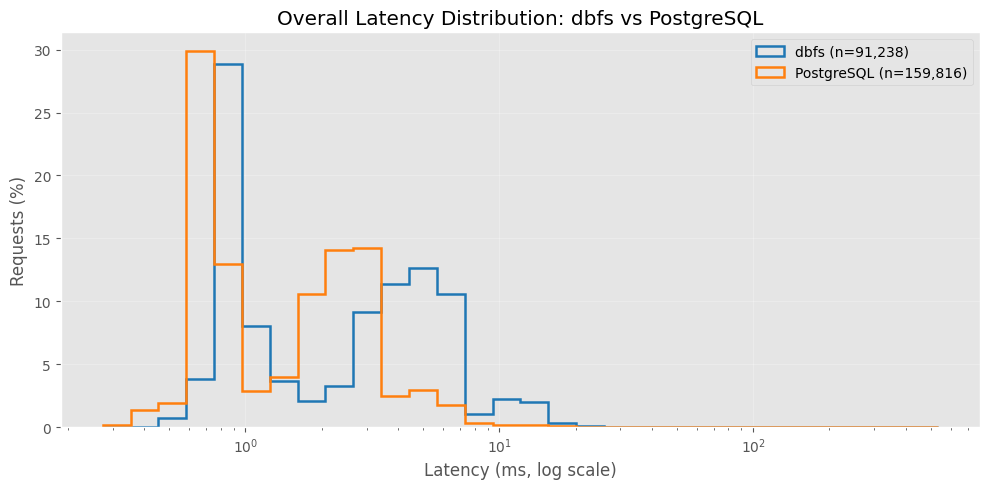

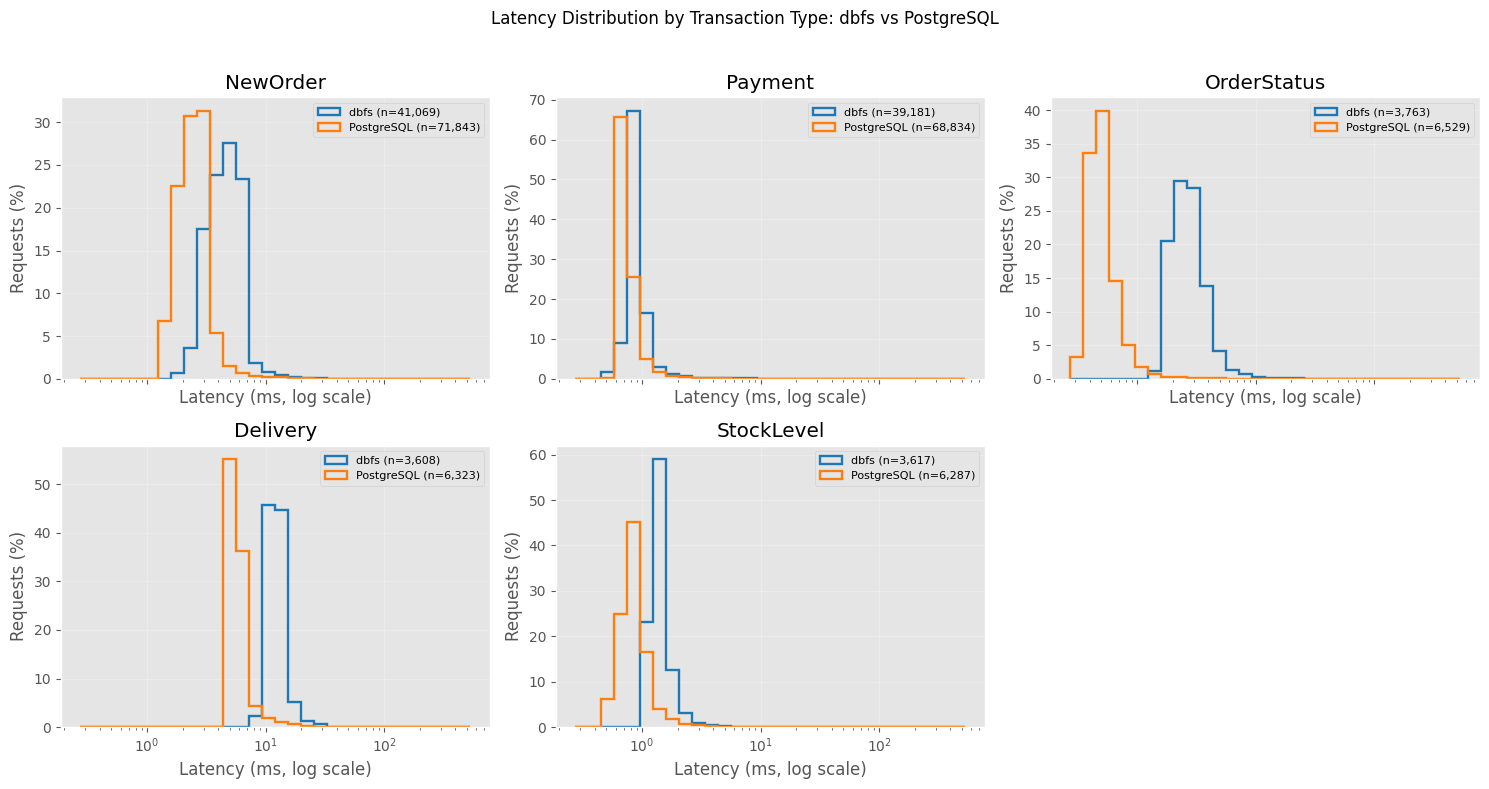

In [5]:
raw_latency_frames = []
for engine, run in runs.items():
    frame = run['raw_df'][['Transaction Name',
                           'Latency (microseconds)']].copy()
    frame['Engine Key'] = engine
    frame['Engine'] = run['display_name']
    frame['Latency (ms)'] = (
        pd.to_numeric(frame['Latency (microseconds)'], errors='coerce') / 1000)
    raw_latency_frames.append(frame.dropna(subset=['Latency (ms)']))

raw_latency_df = pd.concat(raw_latency_frames, ignore_index=True)
raw_latency_df = raw_latency_df[raw_latency_df['Latency (ms)'] > 0]
latency_bin_edges = np.geomspace(raw_latency_df['Latency (ms)'].min(),
                                 raw_latency_df['Latency (ms)'].max(),
                                 num=31)

fig, axis = plt.subplots(figsize=(10, 5))
for engine, engine_df in raw_latency_df.groupby('Engine Key', sort=False):
    latency_ms = engine_df['Latency (ms)']
    axis.hist(latency_ms,
              bins=latency_bin_edges,
              weights=np.full(len(latency_ms), 100 / len(latency_ms)),
              histtype='step',
              linewidth=1.8,
              color=engine_colors[engine],
              label=f"{runs[engine]['display_name']} (n={len(latency_ms):,})")
axis.set_xscale('log')
axis.set_title('Overall Latency Distribution: dbfs vs PostgreSQL')
axis.set_xlabel('Latency (ms, log scale)')
axis.set_ylabel('Requests (%)')
axis.grid(True, alpha=0.25)
axis.legend()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
axes = axes.ravel()

for axis, transaction_name in zip(axes, transaction_names):
    for engine, run in runs.items():
        latency_ms = raw_latency_df.loc[
            (raw_latency_df['Engine Key'] == engine) &
            (raw_latency_df['Transaction Name'] == transaction_name),
            'Latency (ms)',
        ]
        if latency_ms.empty:
            continue
        axis.hist(latency_ms,
                  bins=latency_bin_edges,
                  weights=np.full(len(latency_ms), 100 / len(latency_ms)),
                  histtype='step',
                  linewidth=1.7,
                  color=engine_colors[engine],
                  label=f"{run['display_name']} (n={len(latency_ms):,})")
    axis.set_xscale('log')
    axis.set_title(transaction_name)
    axis.set_xlabel('Latency (ms, log scale)')
    axis.set_ylabel('Requests (%)')
    axis.grid(True, alpha=0.25)
    axis.legend(fontsize=8)

for axis in axes[len(transaction_names):]:
    axis.set_visible(False)

fig.suptitle('Latency Distribution by Transaction Type: dbfs vs PostgreSQL')
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

In [6]:
variability_rows = []
for (engine, transaction_name), group in raw_latency_df.groupby(
    ['Engine', 'Transaction Name'], sort=False):
    latency_ms = group['Latency (ms)']
    variability_rows.append({
        'Engine': engine,
        'Transaction': transaction_name,
        'Requests': len(latency_ms),
        'Mean (ms)': latency_ms.mean(),
        'Std Dev (ms)': latency_ms.std(),
        'CV': latency_ms.std() / latency_ms.mean(),
        'P25 (ms)': latency_ms.quantile(0.25),
        'Median (ms)': latency_ms.median(),
        'P75 (ms)': latency_ms.quantile(0.75),
        'P95 (ms)': latency_ms.quantile(0.95),
        'P99 (ms)': latency_ms.quantile(0.99),
        'Maximum (ms)': latency_ms.max(),
    })

latency_variability_df = pd.DataFrame(variability_rows).sort_values(
    ['Engine', 'Median (ms)'])
display(latency_variability_df)

,Engine,Transaction,Requests,Mean (ms),Std Dev (ms),CV,P25 (ms),Median (ms),P75 (ms),P95 (ms),P99 (ms),Maximum (ms)
9,PostgreSQL,OrderStatus,6529,0.558,0.459,0.823,0.425,0.487,0.575,0.884,1.681,19.483
5,PostgreSQL,Payment,68834,0.821,1.272,1.548,0.672,0.712,0.789,1.131,2.398,150.917
7,PostgreSQL,StockLevel,6287,0.933,1.147,1.230,0.724,0.828,0.960,1.398,2.612,52.658
6,PostgreSQL,NewOrder,71843,2.687,3.451,1.284,1.976,2.469,2.955,3.843,7.349,430.295
8,PostgreSQL,Delivery,6323,6.253,4.308,0.689,5.332,5.606,6.075,8.756,16.334,170.551
0,dbfs,Payment,39181,0.956,0.865,0.905,0.813,0.871,0.952,1.286,2.484,103.923
4,dbfs,StockLevel,3617,1.477,0.716,0.485,1.255,1.364,1.516,2.063,3.215,23.849
3,dbfs,OrderStatus,3763,2.921,1.802,0.617,2.141,2.646,3.264,4.747,8.016,66.318
1,dbfs,NewOrder,41069,4.842,3.169,0.654,3.532,4.617,5.765,6.888,11.663,338.739
2,dbfs,Delivery,3608,12.854,9.478,0.737,11.363,12.175,13.108,16.651,24.982,536.282


## Raw request latency over time by transaction type

Each point is one request from `raw.csv`. The first chart combines all transaction types, followed by separate charts for each type. dbfs is blue and PostgreSQL is orange. The dotted lines use the right-hand axis and show request counts in five-second windows. This avoids treating unstable percentiles from one or two low-frequency requests as if they represented the whole window.

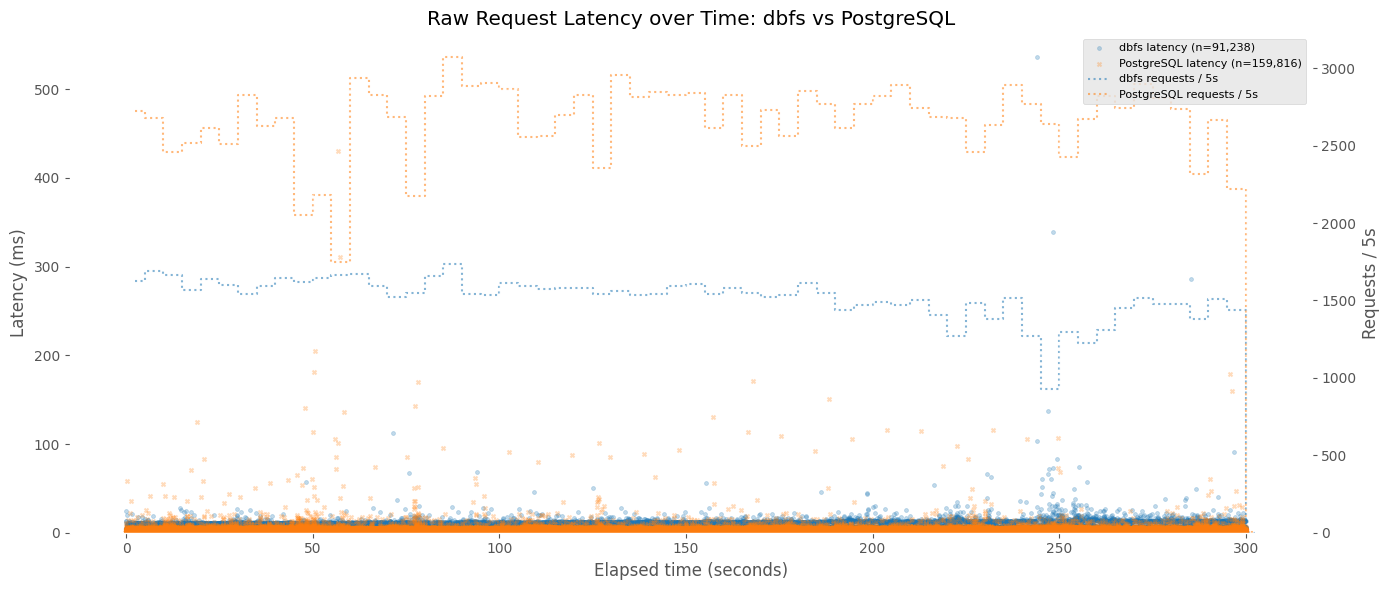

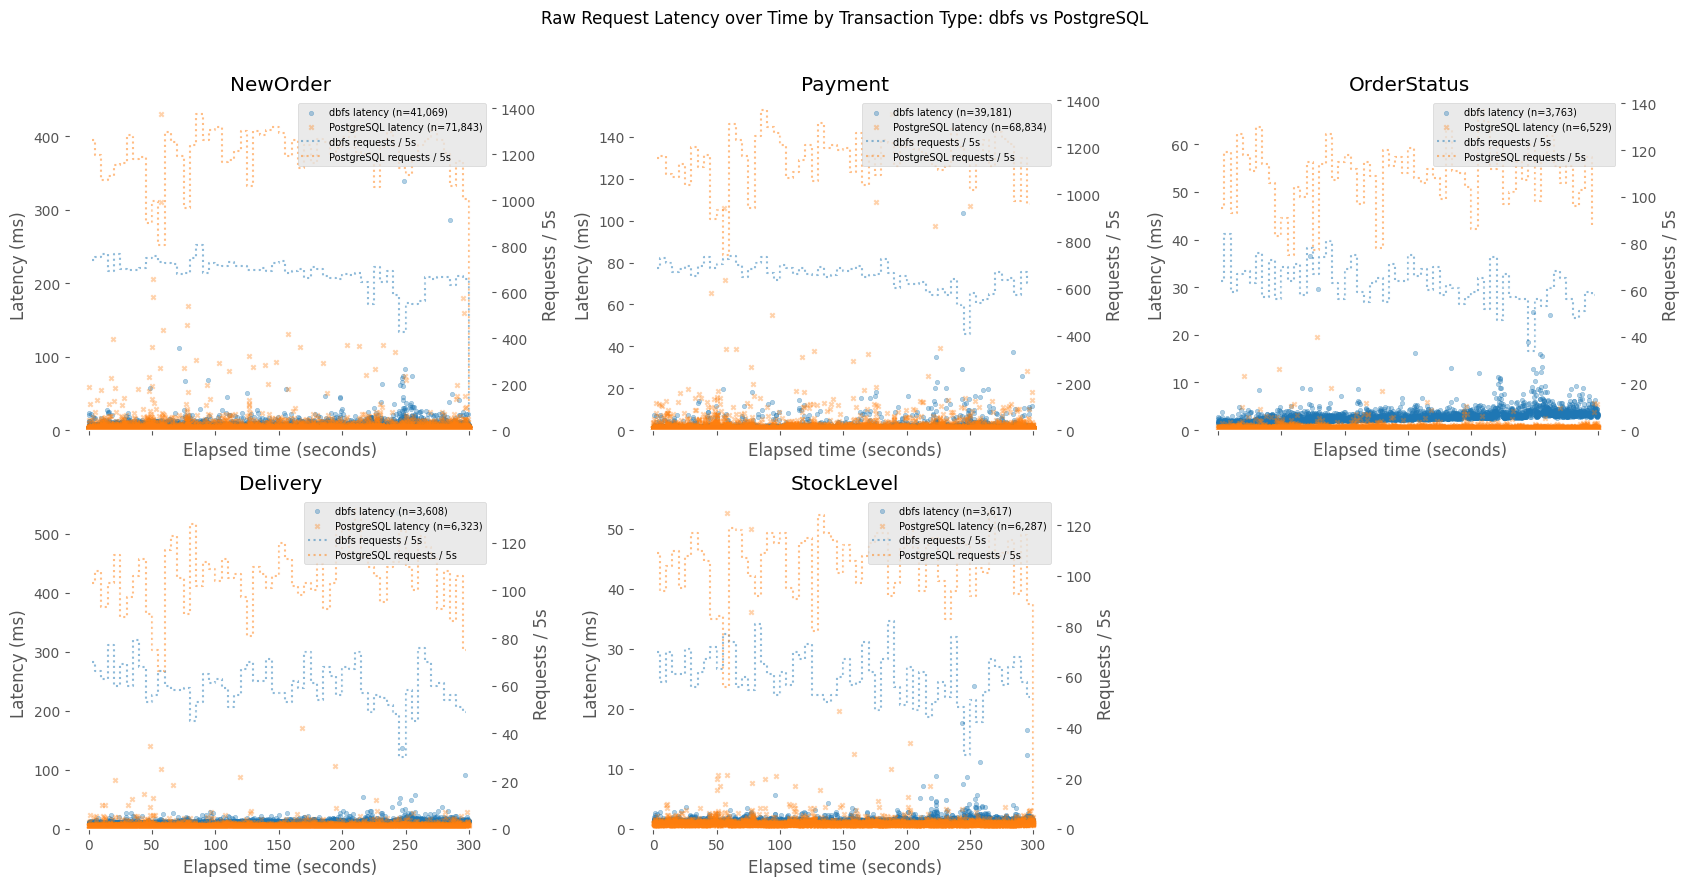

In [7]:
request_count_window_seconds = 5
request_frames = []

for engine, run in runs.items():
    request_df = run['raw_df'][[
        'Transaction Name',
        'Start Time (microseconds)',
        'Latency (microseconds)',
    ]].copy()
    request_df['Start Time'] = pd.to_numeric(
        request_df['Start Time (microseconds)'], errors='coerce')
    request_df['Latency (ms)'] = pd.to_numeric(
        request_df['Latency (microseconds)'], errors='coerce') / 1000
    request_df = request_df.dropna(subset=['Start Time', 'Latency (ms)'])
    request_df = request_df[request_df['Latency (ms)'] > 0]

    start_delta = request_df['Start Time'] - request_df['Start Time'].min()
    expected_run_seconds = run['summary'][
        'Elapsed Time (nanoseconds)'] / 1_000_000_000
    start_time_scale = (1_000_000 if start_delta.max() > expected_run_seconds *
                        1000 else 1)
    request_df['Elapsed Time (seconds)'] = start_delta / start_time_scale
    request_df['Window Start (seconds)'] = (
        request_df['Elapsed Time (seconds)'] // request_count_window_seconds *
        request_count_window_seconds)
    request_df['Engine Key'] = engine
    request_df['Engine'] = run['display_name']
    request_frames.append(request_df)

request_latency_df = pd.concat(request_frames, ignore_index=True)

fig, axis = plt.subplots(figsize=(14, 6))
count_axis = axis.twinx()
for engine, run in runs.items():
    engine_df = request_latency_df[request_latency_df['Engine Key'] == engine]
    request_counts = engine_df.groupby('Window Start (seconds)').size()
    axis.scatter(
        engine_df['Elapsed Time (seconds)'],
        engine_df['Latency (ms)'],
        s=8,
        alpha=0.28,
        color=engine_colors[engine],
        marker=engine_markers[engine],
        rasterized=True,
        label=f"{run['display_name']} latency (n={len(engine_df):,})",
    )
    count_axis.step(
        request_counts.index + request_count_window_seconds / 2,
        request_counts.values,
        where='mid',
        color=engine_colors[engine],
        alpha=0.55,
        linestyle=':',
        label=
        f"{run['display_name']} requests / {request_count_window_seconds}s",
    )
axis.set_zorder(count_axis.get_zorder() + 1)
axis.patch.set_visible(False)
axis.set_title('Raw Request Latency over Time: dbfs vs PostgreSQL')
axis.set_xlabel('Elapsed time (seconds)')
axis.set_ylabel('Latency (ms)')
axis.set_ylim(bottom=0)
count_axis.set_ylabel(f'Requests / {request_count_window_seconds}s')
count_axis.set_ylim(bottom=0)
axis.grid(True, alpha=0.25)
latency_handles, latency_labels = axis.get_legend_handles_labels()
count_handles, count_labels = count_axis.get_legend_handles_labels()
axis.legend(latency_handles + count_handles,
            latency_labels + count_labels,
            loc='upper right',
            fontsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex=True)
axes = axes.ravel()

for axis, transaction_name in zip(axes, transaction_names):
    count_axis = axis.twinx()
    for engine, run in runs.items():
        transaction_df = request_latency_df[
            (request_latency_df['Engine Key'] == engine)
            & (request_latency_df['Transaction Name'] == transaction_name)]
        request_counts = transaction_df.groupby(
            'Window Start (seconds)').size()
        axis.scatter(
            transaction_df['Elapsed Time (seconds)'],
            transaction_df['Latency (ms)'],
            s=10,
            alpha=0.35,
            color=engine_colors[engine],
            marker=engine_markers[engine],
            rasterized=True,
            label=f"{run['display_name']} latency (n={len(transaction_df):,})",
        )
        count_axis.step(
            request_counts.index + request_count_window_seconds / 2,
            request_counts.values,
            where='mid',
            color=engine_colors[engine],
            alpha=0.5,
            linestyle=':',
            label=
            f"{run['display_name']} requests / {request_count_window_seconds}s",
        )
    axis.set_zorder(count_axis.get_zorder() + 1)
    axis.patch.set_visible(False)
    axis.set_title(transaction_name)
    axis.set_xlabel('Elapsed time (seconds)')
    axis.set_ylabel('Latency (ms)')
    axis.set_ylim(bottom=0)
    count_axis.set_ylabel(f'Requests / {request_count_window_seconds}s')
    count_axis.set_ylim(bottom=0)
    axis.grid(True, alpha=0.25)

    latency_handles, latency_labels = axis.get_legend_handles_labels()
    count_handles, count_labels = count_axis.get_legend_handles_labels()
    axis.legend(latency_handles + count_handles,
                latency_labels + count_labels,
                loc='upper right',
                fontsize=7)

for axis in axes[len(transaction_names):]:
    axis.set_visible(False)

fig.suptitle('Raw Request Latency over Time by Transaction Type: '
             'dbfs vs PostgreSQL')
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## SQL-shape latency

The query-trace files contain aggregates by normalized SQL shape. They can rank total time, mean latency, and maximum latency, but they do not contain individual executions and therefore cannot produce per-shape latency histograms.

Top query shapes for dbfs


,kind,executions,time_share_pct,total_elapsed_ms,mean_elapsed_ms,p95_elapsed_ms,max_elapsed_ms,failures,sample_sql
0,QUERY,484728,20.021,"57,329.977",0.118,<NA>,259.401,0,"SELECT S_QUANTITY, S_DATA, S_DIST_01, S_DIST_0..."
1,QUERY,485216,15.438,"44,207.983",0.091,<NA>,204.266,0,"SELECT I_PRICE, I_NAME , I_DATA FROM item WHER..."
2,UPDATE,480297,14.933,"42,761.032",0.089,<NA>,62.594,0,"UPDATE stock SET S_QUANTITY = 66 , S_YTD = S_Y..."
3,QUERY,43100,7.136,"20,435.389",0.474,<NA>,110.227,0,SELECT NO_O_ID FROM new_order WHERE NO_D_ID = ...
4,BATCH_UPDATE,48114,5.565,"15,936.885",0.331,<NA>,56.592,0,"INSERT INTO order_line (OL_O_ID, OL_D_ID, OL_W..."
5,QUERY,4437,3.003,"8,599.369",1.938,<NA>,49.559,0,"SELECT O_ID, O_CARRIER_ID, O_ENTRY_D FROM oord..."
6,UPDATE,43100,2.548,"7,297.090",0.169,<NA>,41.682,0,UPDATE order_line SET OL_DELIVERY_D = '2026-09...
7,QUERY,30462,2.350,"6,729.782",0.220,<NA>,69.600,0,"SELECT C_FIRST, C_MIDDLE, C_ID, C_STREET_1, C_..."
8,QUERY,4280,1.971,"5,645.433",1.319,<NA>,21.258,0,SELECT COUNT(DISTINCT (S_I_ID)) AS STOCK_COUNT...
9,QUERY,48602,1.908,"5,463.280",0.112,<NA>,12.218,0,"SELECT C_DISCOUNT, C_LAST, C_CREDIT FROM custo..."


Top query shapes for PostgreSQL


,kind,executions,time_share_pct,total_elapsed_ms,mean_elapsed_ms,p95_elapsed_ms,max_elapsed_ms,failures,sample_sql
0,QUERY,847712,20.533,"44,518.215",0.052,<NA>,224.242,0,"SELECT S_QUANTITY, S_DATA, S_DIST_01, S_DIST_0..."
1,QUERY,848587,18.460,"40,022.986",0.047,<NA>,115.439,0,"SELECT I_PRICE, I_NAME , I_DATA FROM item WHER..."
2,UPDATE,839846,8.492,"18,411.169",0.021,<NA>,10.928,0,"INSERT INTO order_line (OL_O_ID, OL_D_ID, OL_W..."
3,UPDATE,839846,5.566,"12,066.811",0.014,<NA>,3.099,0,"UPDATE stock SET S_QUANTITY = 29 , S_YTD = S_Y..."
4,UPDATE,74490,3.718,"8,061.485",0.108,<NA>,33.442,0,UPDATE order_line SET OL_DELIVERY_D = '2026-09...
5,UPDATE,84864,2.694,"5,840.843",0.068,<NA>,19.768,0,"INSERT INTO oorder (O_ID, O_D_ID, O_W_ID, O_C_..."
6,QUERY,7421,2.546,"5,519.516",0.743,<NA>,52.079,0,SELECT COUNT(DISTINCT (S_I_ID)) AS STOCK_COUNT...
7,UPDATE,81401,2.478,"5,373.400",0.066,<NA>,10.284,0,"INSERT INTO history (H_C_D_ID, H_C_W_ID, H_C_I..."
8,QUERY,84864,2.474,"5,364.857",0.063,<NA>,49.139,0,"SELECT C_DISCOUNT, C_LAST, C_CREDIT FROM custo..."
9,UPDATE,81401,2.327,"5,044.242",0.061,<NA>,23.295,0,UPDATE warehouse SET W_YTD = W_YTD + 4586.5498...


Shared query shape overlap


,dbfs_shapes,postgres_shapes,shared_shapes,dbfs_only,postgres_only
0,31,41,31,0,10


,kind_dbfs,executions_dbfs,executions_postgres,total_elapsed_ms_dbfs,total_elapsed_ms_postgres,mean_elapsed_ms_dbfs,mean_elapsed_ms_postgres,mean_latency_delta_ms,mean_latency_ratio_dbfs_to_postgres,max_elapsed_ms_dbfs,max_elapsed_ms_postgres,sample_sql
0,QUERY,484728,847712,"57,329.977","44,518.215",0.118,0.052,0.066,2.269,259.401,224.242,"SELECT S_QUANTITY, S_DATA, S_DIST_01, S_DIST_0..."
1,QUERY,485216,848587,"44,207.983","40,022.986",0.091,0.047,0.044,1.936,204.266,115.439,"SELECT I_PRICE, I_NAME , I_DATA FROM item WHER..."
2,UPDATE,480297,839846,"42,761.032","12,066.811",0.089,0.014,0.075,6.357,62.594,3.099,"UPDATE stock SET S_QUANTITY = 66 , S_YTD = S_Y..."
4,BATCH_UPDATE,48114,839846,"15,936.885","18,411.169",0.331,0.021,0.310,15.762,56.592,10.928,"INSERT INTO order_line (OL_O_ID, OL_D_ID, OL_W..."
3,QUERY,43100,74490,"20,435.389","3,961.845",0.474,0.053,0.421,8.943,110.227,10.037,SELECT NO_O_ID FROM new_order WHERE NO_D_ID = ...
6,UPDATE,43100,74490,"7,297.090","8,061.485",0.169,0.108,0.061,1.565,41.682,33.442,UPDATE order_line SET OL_DELIVERY_D = '2026-09...
7,QUERY,30462,53567,"6,729.782","4,549.671",0.220,0.084,0.136,2.619,69.600,12.341,"SELECT C_FIRST, C_MIDDLE, C_ID, C_STREET_1, C_..."
8,QUERY,4280,7421,"5,645.433","5,519.516",1.319,0.743,0.576,1.775,21.258,52.079,SELECT COUNT(DISTINCT (S_I_ID)) AS STOCK_COUNT...
9,QUERY,48602,84864,"5,463.280","5,364.857",0.112,0.063,0.049,1.778,12.218,49.139,"SELECT C_DISCOUNT, C_LAST, C_CREDIT FROM custo..."
12,UPDATE,48602,84864,"4,345.080","5,840.843",0.089,0.068,0.021,1.309,17.927,19.768,"INSERT INTO oorder (O_ID, O_D_ID, O_W_ID, O_C_..."


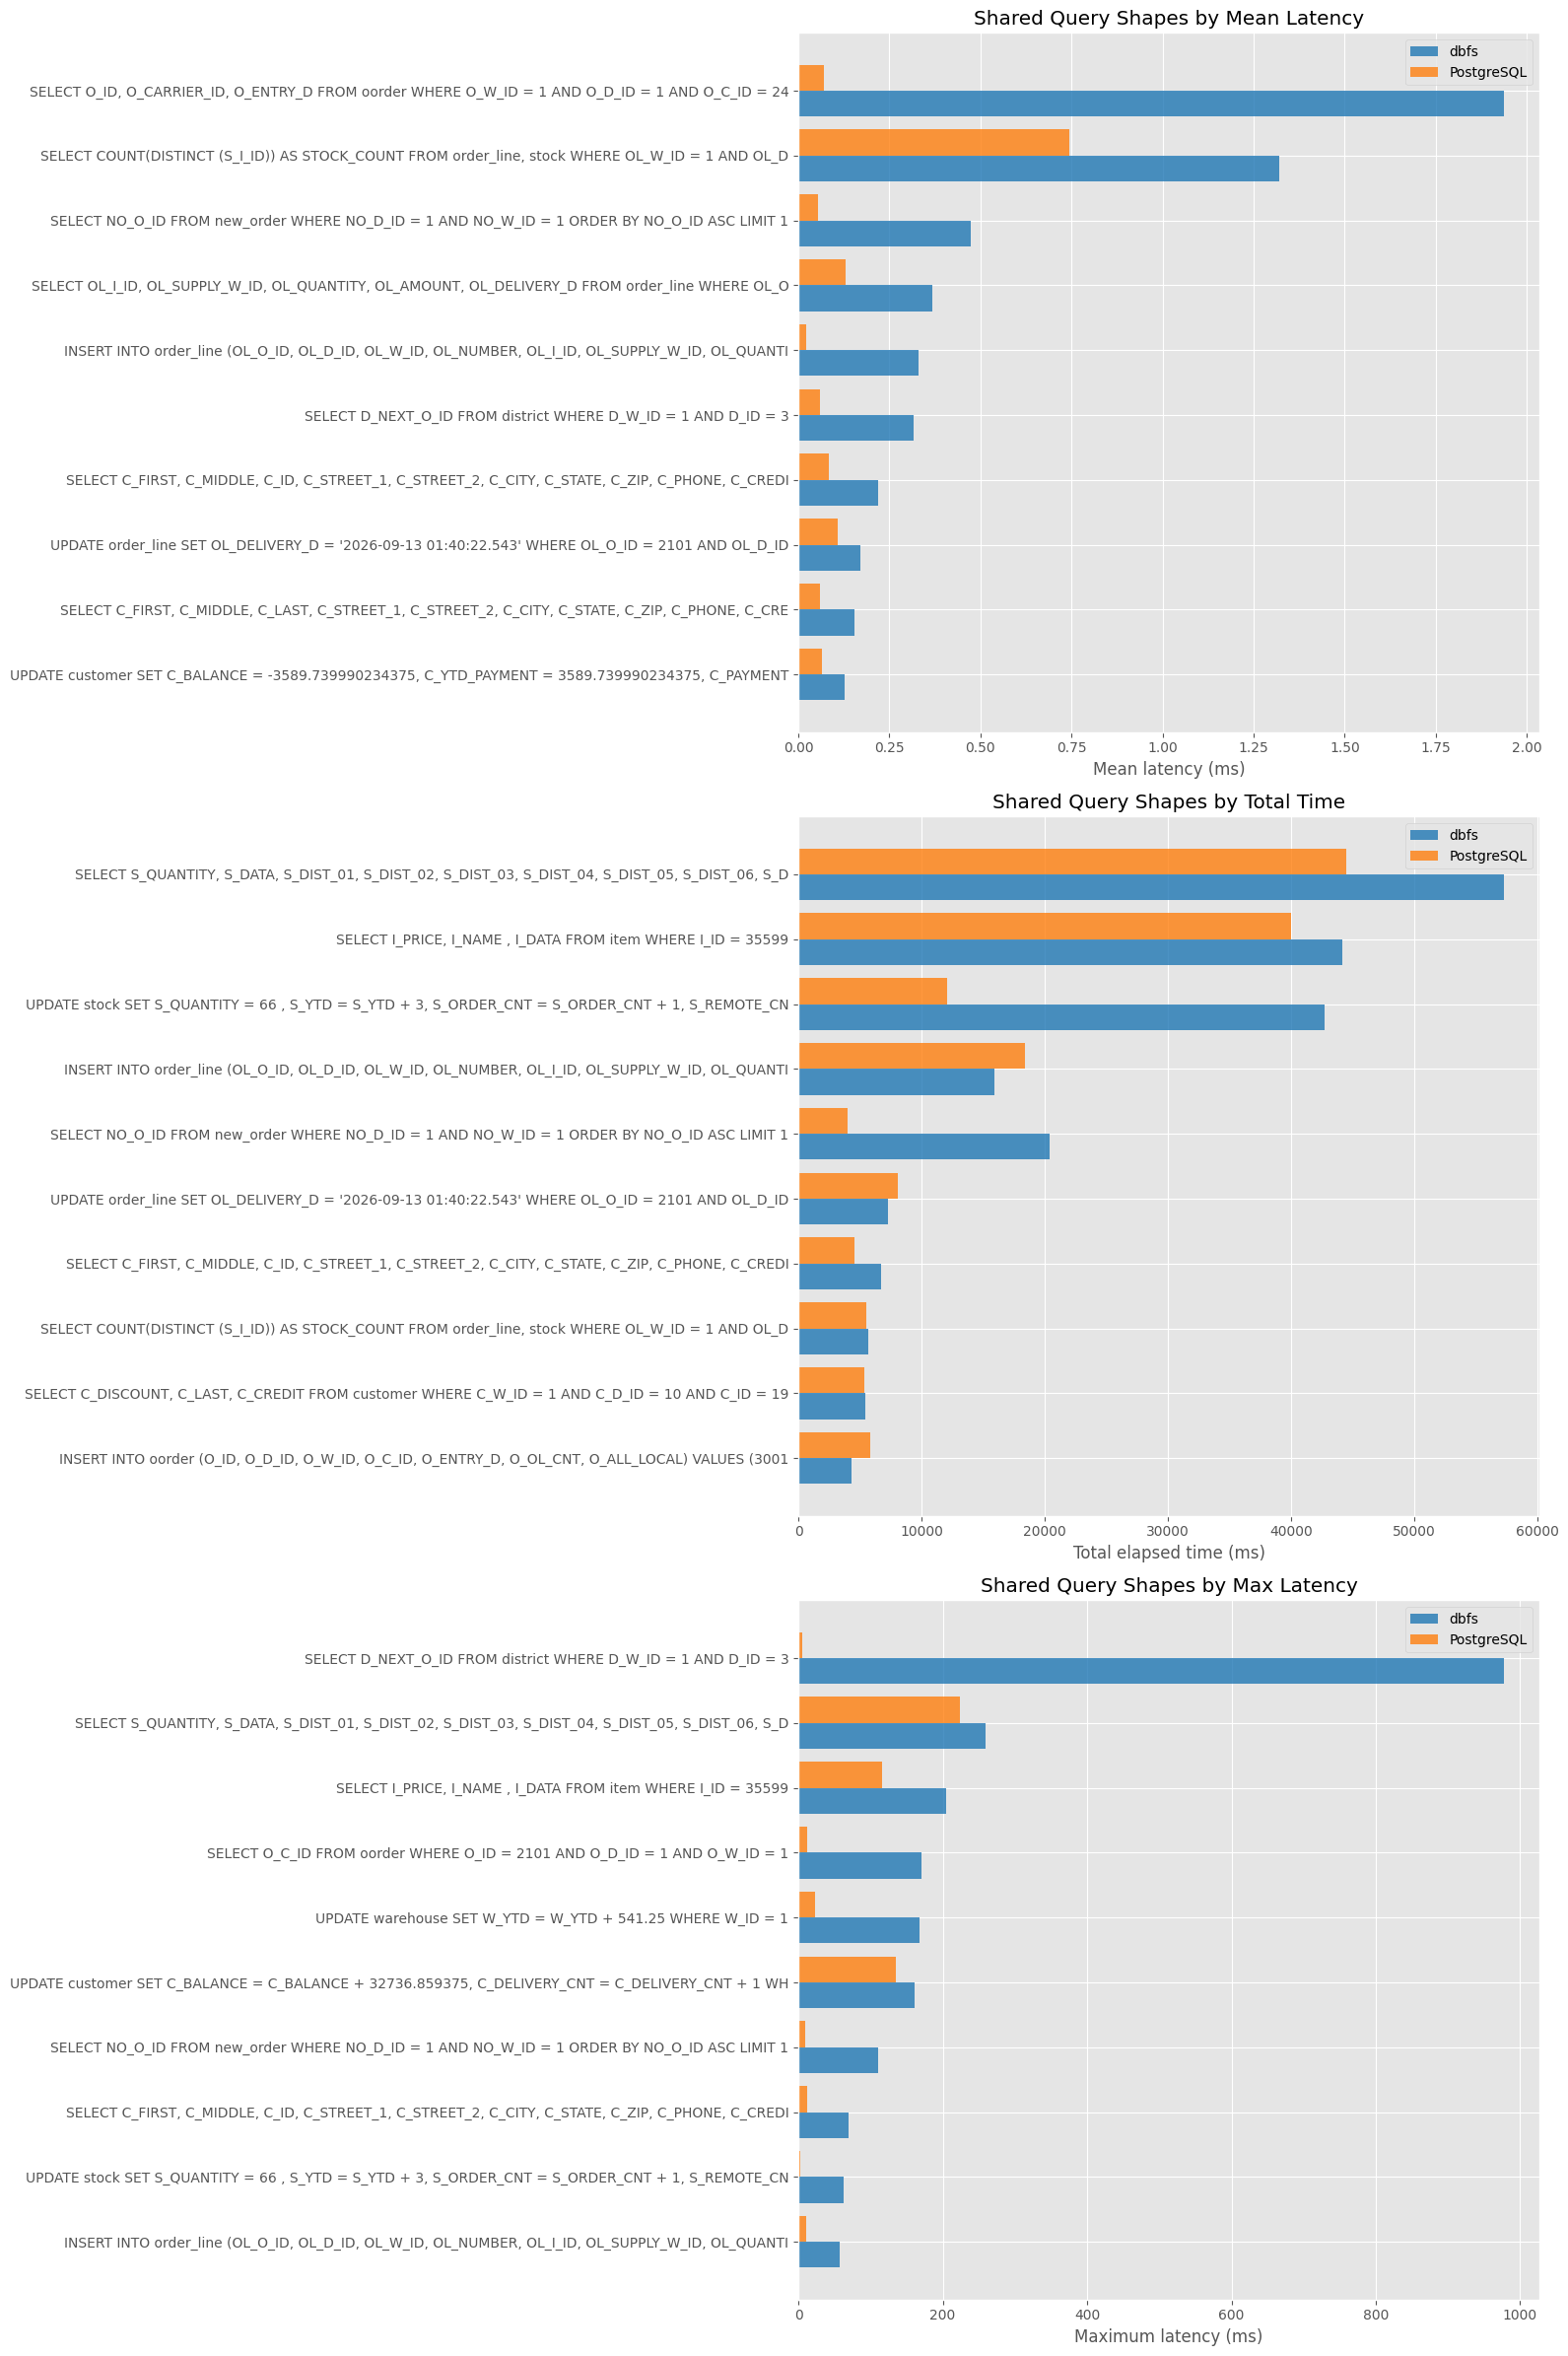

In [8]:
def summarize_dbfs_query_trace(trace_df):
    summary_df = trace_df.copy()
    summary_df['sample_sql'] = summary_df['sample_sql'].fillna(
        summary_df['shape_key'])
    summary_df['total_elapsed_ms'] = summary_df['total_elapsed_us'] / 1000.0
    summary_df['mean_elapsed_ms'] = summary_df['mean_elapsed_us'] / 1000.0
    summary_df['p95_elapsed_ms'] = pd.NA
    summary_df['max_elapsed_ms'] = summary_df['max_elapsed_us'] / 1000.0
    summary_df = summary_df.sort_values(['total_elapsed_ms', 'executions'],
                                        ascending=[False, False])
    return summary_df[[
        'kind',
        'shape_key',
        'sample_sql',
        'executions',
        'total_elapsed_ms',
        'mean_elapsed_ms',
        'p95_elapsed_ms',
        'max_elapsed_ms',
        'failures',
    ]]


def summarize_postgres_server_query_trace(trace_df):
    summary_df = trace_df.copy()
    summary_df['kind'] = 'QUERY'
    summary_df['shape_key'] = summary_df['query'].str.replace(
        r'\s+', ' ', regex=True).str.strip()
    summary_df['sample_sql'] = summary_df['query']
    summary_df['executions'] = summary_df['calls']
    summary_df['total_elapsed_ms'] = summary_df['total_exec_time']
    summary_df['mean_elapsed_ms'] = summary_df['mean_exec_time']
    summary_df['p95_elapsed_ms'] = pd.NA
    summary_df['max_elapsed_ms'] = summary_df['max_exec_time']
    summary_df['failures'] = 0
    summary_df = summary_df.sort_values(['total_elapsed_ms', 'executions'],
                                        ascending=[False, False])
    return summary_df[[
        'kind',
        'shape_key',
        'sample_sql',
        'executions',
        'total_elapsed_ms',
        'mean_elapsed_ms',
        'p95_elapsed_ms',
        'max_elapsed_ms',
        'failures',
    ]]


def summarize_postgres_query_trace(trace_df):
    if {
            'query', 'calls', 'total_exec_time', 'mean_exec_time',
            'max_exec_time'
    }.issubset(trace_df.columns):
        return summarize_postgres_server_query_trace(trace_df)
    return summarize_dbfs_query_trace(trace_df)


def escape_plot_label(text):
    return text.replace('$', r'\$')


def build_shared_trace_comparison(trace_summaries):
    if not {'dbfs', 'postgres'}.issubset(trace_summaries):
        return None

    shared_df = trace_summaries['dbfs'].merge(
        trace_summaries['postgres'],
        on='shape_key',
        how='inner',
        suffixes=('_dbfs', '_postgres'),
    )
    if shared_df.empty:
        return shared_df

    shared_df['sample_sql'] = shared_df['sample_sql_dbfs'].fillna(
        shared_df['sample_sql_postgres'])
    shared_df['combined_total_elapsed_ms'] = (
        shared_df['total_elapsed_ms_dbfs'] +
        shared_df['total_elapsed_ms_postgres'])
    shared_df['combined_mean_elapsed_ms'] = shared_df[[
        'mean_elapsed_ms_dbfs',
        'mean_elapsed_ms_postgres',
    ]].max(axis=1)
    shared_df['combined_max_elapsed_ms'] = shared_df[[
        'max_elapsed_ms_dbfs',
        'max_elapsed_ms_postgres',
    ]].max(axis=1)
    shared_df['label'] = shared_df['sample_sql'].str.slice(0, 96)
    shared_df['plot_label'] = shared_df['label'].map(escape_plot_label)
    shared_df['mean_latency_delta_ms'] = (
        shared_df['mean_elapsed_ms_dbfs'] -
        shared_df['mean_elapsed_ms_postgres'])
    shared_df['mean_latency_ratio_dbfs_to_postgres'] = (
        shared_df['mean_elapsed_ms_dbfs'] /
        shared_df['mean_elapsed_ms_postgres'].replace(0, np.nan))
    return shared_df.sort_values(
        ['combined_total_elapsed_ms', 'combined_max_elapsed_ms'],
        ascending=[False, False],
    )


trace_summaries = {}
for engine, run in runs.items():
    trace_df = run['query_trace_df']
    if trace_df is None or trace_df.empty:
        print(
            f"{run['display_name']}: {query_trace_filenames[engine]} was not found."
        )
        continue

    if engine == 'dbfs':
        engine_summary_df = summarize_dbfs_query_trace(trace_df.copy())
    else:
        engine_summary_df = summarize_postgres_query_trace(trace_df.copy())

    engine_summary_df['Engine'] = run['display_name']
    engine_summary_df['time_share_pct'] = (
        engine_summary_df['total_elapsed_ms'] /
        engine_summary_df['total_elapsed_ms'].sum() * 100)
    engine_summary_df['label'] = engine_summary_df['sample_sql'].str.slice(
        0, 96)
    engine_summary_df['plot_label'] = engine_summary_df['label'].map(
        escape_plot_label)
    trace_summaries[engine] = engine_summary_df

for engine, summary_df in trace_summaries.items():
    display_name = runs[engine]['display_name']
    print(f'Top query shapes for {display_name}')
    display(summary_df[[
        'kind',
        'executions',
        'time_share_pct',
        'total_elapsed_ms',
        'mean_elapsed_ms',
        'p95_elapsed_ms',
        'max_elapsed_ms',
        'failures',
        'sample_sql',
    ]].head(15))

shared_trace_df = build_shared_trace_comparison(trace_summaries)
if shared_trace_df is not None:
    overlap_summary_df = pd.DataFrame([{
        'dbfs_shapes':
        len(trace_summaries['dbfs']),
        'postgres_shapes':
        len(trace_summaries['postgres']),
        'shared_shapes':
        len(shared_trace_df),
        'dbfs_only':
        len(trace_summaries['dbfs']) - len(shared_trace_df),
        'postgres_only':
        len(trace_summaries['postgres']) - len(shared_trace_df),
    }])
    print('Shared query shape overlap')
    display(overlap_summary_df)

    display(shared_trace_df[[
        'kind_dbfs',
        'executions_dbfs',
        'executions_postgres',
        'total_elapsed_ms_dbfs',
        'total_elapsed_ms_postgres',
        'mean_elapsed_ms_dbfs',
        'mean_elapsed_ms_postgres',
        'mean_latency_delta_ms',
        'mean_latency_ratio_dbfs_to_postgres',
        'max_elapsed_ms_dbfs',
        'max_elapsed_ms_postgres',
        'sample_sql',
    ]].head(15))

    fig, axes = plt.subplots(3, 1, figsize=(16, 24))

    plot_specs = [
        (
            'combined_mean_elapsed_ms',
            'mean_elapsed_ms',
            'Shared Query Shapes by Mean Latency',
            'Mean latency (ms)',
        ),
        (
            'combined_total_elapsed_ms',
            'total_elapsed_ms',
            'Shared Query Shapes by Total Time',
            'Total elapsed time (ms)',
        ),
        (
            'combined_max_elapsed_ms',
            'max_elapsed_ms',
            'Shared Query Shapes by Max Latency',
            'Maximum latency (ms)',
        ),
    ]

    for axis, (combined_metric, metric, title,
               x_label) in zip(axes, plot_specs):
        top_df = shared_trace_df.nlargest(
            10, combined_metric).sort_values(combined_metric)
        positions = list(range(len(top_df)))
        axis.barh(
            [position - 0.2 for position in positions],
            top_df[f'{metric}_dbfs'],
            height=0.4,
            label='dbfs',
            color=engine_colors['dbfs'],
            alpha=0.8,
        )
        axis.barh(
            [position + 0.2 for position in positions],
            top_df[f'{metric}_postgres'],
            height=0.4,
            label='PostgreSQL',
            color=engine_colors['postgres'],
            alpha=0.8,
        )
        axis.set_yticks(positions)
        axis.set_yticklabels(top_df['plot_label'])
        axis.set_title(title)
        axis.set_xlabel(x_label)

    for axis in axes:
        axis.legend()
    fig.tight_layout()
    plt.show()